# Information extraction

## 1. Imports

In [ ]:
# General
import os

# Keywords extraction
import yake

# Wordcloud
from collections import Counter
from wordcloud import WordCloud
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

# Named entities recognition
from collections import defaultdict
import spacy
from spacy.lang.fr.examples import sentences

# Sentiment analysis
from textblob import Blobber
from textblob_fr import PatternTagger, PatternAnalyzer



!uv pip install sentencepiece
!uv pip install transformers>=5.19.0
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import pipeline

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\senek\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 2. Constants

In [63]:
YEAR = 1962
DATA_PATH = "../../data/txt/"
TEMP_PATH = '../../data/tmp'

## 3. Keywords

In [ ]:
# Instantiation of keywords extractor
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_extractor

# List files corresponding to the year
files = [f for f in os.listdir(DATA_PATH) if f.endswith('.txt') and str(YEAR) in f]

# Regroupment of files by month
repartition = Counter(f.split('_')[2][5:7] for f in files) # Split by "_" and extract MM from yyyy-MM-dd from the filename
repartition_sorted = sorted(repartition.items()) # Had to add .items() otherwise it only displayed the sorted months

print(f"There is {len(files)} files for year {YEAR}.\n This is the repartition: {repartition_sorted}\n")

# Extraction of keywords and bigrams from the files
bigrams_count = Counter()
keywords_count = Counter()

with open(os.path.join(TEMP_PATH, f'{YEAR}_bigrams.txt'), 'w', encoding='utf-8') as bigrams_file:
    with open(os.path.join(TEMP_PATH, f'{YEAR}_keywords.txt'), 'w', encoding='utf-8') as keywords_file:
        for f in sorted(files):
            text = open(os.path.join(DATA_PATH, f), 'r', encoding="utf-8").read()
            keywords = kw_extractor.extract_keywords(text)
            kept = []
            keywords_only = []
            for kw, score in keywords:
                words = kw.split()
                keywords_only.append(kw)
                if len(words) == 2:
                    kept.append(kw)
            
            # Export the list of keywords and bigrams in two distinct files
            keywords_file.write(f"{f} mentions these keywords: {', '.join(keywords_only)}...\n")
            bigrams_file.write(f"{f} mentions these bigrams: {', '.join(kept)}...\n")
            
            # Count bigrams and keywords for aggregation
            for kw in keywords_only:            
                keywords_count[kw.lower()] += 1
            for bg in kept:
                bigrams_count[bg.lower()] += 1

There is 100 files for year 1962.
 This is the repartition: [('01', 7), ('02', 6), ('03', 7), ('04', 14), ('05', 10), ('06', 10), ('07', 5), ('08', 9), ('09', 9), ('10', 6), ('11', 7), ('12', 10)]



### Aggregations

In [80]:
# Top 30 keywords
keywords_count.most_common(30)

[('bruxelles', 74),
 ('rue', 54),
 ('prix', 45),
 ('tél', 40),
 ('brux', 35),
 ('belgique', 34),
 ('grand', 32),
 ('van', 31),
 ('ans', 28),
 ('part', 28),
 ('rossel', 26),
 ('téléph', 26),
 ('france', 25),
 ('soir', 25),
 ('d’une', 25),
 ('ecr', 24),
 ('d’un', 23),
 ('place', 22),
 ('qu’il', 22),
 ('ecrire', 21),
 ('faire', 21),
 ('mod', 20),
 ('cours', 19),
 ('centre', 19),
 ('bon', 19),
 ('c’est', 19),
 ('dimanche', 19),
 ('point', 19),
 ('samedi', 19),
 ('service', 18)]

In [81]:
# Top 30 bigrams
bigrams_count.most_common(30)

[('agence rossel', 15),
 ('ecrire agence', 9),
 ('new york', 8),
 ('faire offre', 8),
 ('bruxelles tél', 8),
 ('division iii', 8),
 ('grand prix', 8),
 ('opel rek', 7),
 ('bel app', 7),
 ('musique légère', 7),
 ('rossel num', 6),
 ('van den', 6),
 ('l’agence rossel', 6),
 ('van der', 6),
 ('bon état', 6),
 ('france iii', 6),
 ('musique enregistrée', 6),
 ('tient lieu', 6),
 ('avis tient', 6),
 ('ford motor', 5),
 ('société générale', 5),
 ('cours compensation', 5),
 ('anvers 54-74', 5),
 ('opel rekord', 5),
 ('app. mod', 5),
 ('rue royale', 5),
 ('marché commun', 5),
 ('concert symphonique', 5),
 ('liège 53-68', 4),
 ('colonie congo', 4)]

## Wordcloud

In [125]:
# Stopwords
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem", "brux", "ecr", "tél", "app",
       "très", "part", "ans", "mod", "leurs", "conf", "avant", "lieu", "peu", "gar", "fin",
       "jours", "téléph", "bonne", "terr", "mal", "vis", "toute", "bel", "culs", "quelques",
       "bat", "près", "prés", "car", "mer", "trav", "pers", "pts", "rem", "mat", "tel", "faç",
       "grd", "emp", "bur", "ind", "lux", "max", "min", "adr", "pet", "frs", "ter", "com",
       "cuis", "comm", "llv", "mis", "maz", "hui", "esp", "ler", "mol", "réf", "sam", "fit",
       "mén", "env", "ets", "cav", "fem", "gén", "ent", "pré", "chb", "ouv", "mar", "apr",
       "rue", "bruxelles", "prix", "grand", "place", "soir", "belgique", "cours", "anvers",
       "mois", "centre", "bon", "avenue", "maison", "grande", "agence", "louer", "état", 
       "libre", "villa", "tour", "vue", "vendre", "devant", "terrain", "neuf", "situation",
       "nouveau", "garage", "cherche", "appart", "état", "vend", "sept", "luxe", "cour",
       "vente", "hall", "étage", "rez", "mutuel", "chambre", "opel", "heures", "temps",
       "samedi", "août", "dimanche", "avril", "midi", "lundi", "juin", "mercredi", "année",
       "vendredi", "heure", "semaine", "mardi", "mai", "date", "mars", "cinq", "septembre",
       "jeudi", "matin", "novembre", "saint", "division", "demande", "pays", "ecrire",
       "france", "premier", "service", "équipe", "eau", "points", "liège", "etc", "monsieur",
       "jour", "jean", "repos", "toujours", "partir", "celui", "nationale", "chf", "dernier",
       "uccle", "congo", "fort", "alors", "petit", "paris", "général", "waterloo", "course", 
       "cas", "union", "belle", "madame", "trop", "monde", "chez", "ministre", "déjà", "ordre",
       "beau", "gand", "quatre", "suite", "gros", "ailleurs", "fois", "beaux", "vers", "importante",
       "III", "homme", "voir", "effet", "seul", "société", "porte"]
sw = set(sw)

print(len(sw), "\n")

# List files corresponding to the year
txts = [f for f in os.listdir(DATA_PATH) if os.path.isfile(os.path.join(DATA_PATH, f)) and str(YEAR) in f]

# Store the content of txts in a list
content_list = []
for txt in txts:
    with open(os.path.join(DATA_PATH, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

# Write the content in a file
if not os.path.exists(TEMP_PATH):
    os.mkdir(TEMP_PATH)
with open(os.path.join(TEMP_PATH, f'{YEAR}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

# Function that cleans the file from stopwords and other noise
def clean_text(YEAR, folder=None):
    if folder is None:
        input_path = f"{YEAR}.txt"
        output_path = f"{YEAR}_clean.txt"
    else:
        input_path = f"{folder}/{YEAR}.txt"
        output_path = f"{folder}/{YEAR}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

# Execute the cleaning function
clean_text(YEAR, folder=TEMP_PATH)

# Import the cleaned file 
with open(os.path.join(TEMP_PATH, f'{YEAR}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

# Calculate the most frequent terms
frequencies = Counter(after.split())

for lbl, fr in frequencies.most_common():
    print(f"{lbl} -> {fr}")


397 

FRANCS -> 251
PREMIÈRE -> 247
MARCHÉ -> 242
MUSIQUE -> 241
BELGE -> 235
ENFANTS -> 227
MATCH -> 227
PRÉSIDENT -> 223
PARTIE -> 216
POINT -> 212
JEU -> 200
EUROPE -> 196
ROYAL -> 196
BUREAU -> 195
CONSEIL -> 191
TRAVAIL -> 182
JEUNE -> 179
NOUVELLE -> 176
LOI -> 160
ETAT -> 159
PROGRAMME -> 159
GOUVERNEMENT -> 157
OFFRE -> 151
ÉGALEMENT -> 150
PRÉSENTER -> 149
FRANÇAIS -> 146
III -> 145
JEUNES -> 140
NORD -> 139
LOUISE -> 139
ART -> 139
ELLES -> 139
JARD -> 138
PIERRE -> 138
JUILLET -> 138
RESTE -> 135
ENTRÉE -> 135
DÈS -> 135
VIE -> 134
NAMUR -> 134
SUD -> 132
MILLIONS -> 132
POLITIQUE -> 132
DÉBUT -> 131
JARDIN -> 131
CEUX -> 129
ORGANISATEUR -> 126
DACTYLO -> 126
ANDERLECHT -> 126
CONDITIONS -> 126
HAUT -> 126
ÉQUIPES -> 126
CEPENDANT -> 125
RIEN -> 125
AIR -> 124
HOMMES -> 124
MONS -> 124
CLUB -> 123
OCTOBRE -> 123
BAS -> 122
CONCERT -> 122
PLUSIEURS -> 121
DÉCEMBRE -> 121
DÉPART -> 121
CHAQUE -> 121
DIX -> 121
VICTOIRE -> 121
ASSEZ -> 121
DEUXIÈME -> 121
GUERRE -> 120
PARC ->

In [126]:
# Count the number of unique words
len(frequencies)

66210

In [127]:
# Count the total word occurrence
print(f"{frequencies.total()}")

242871


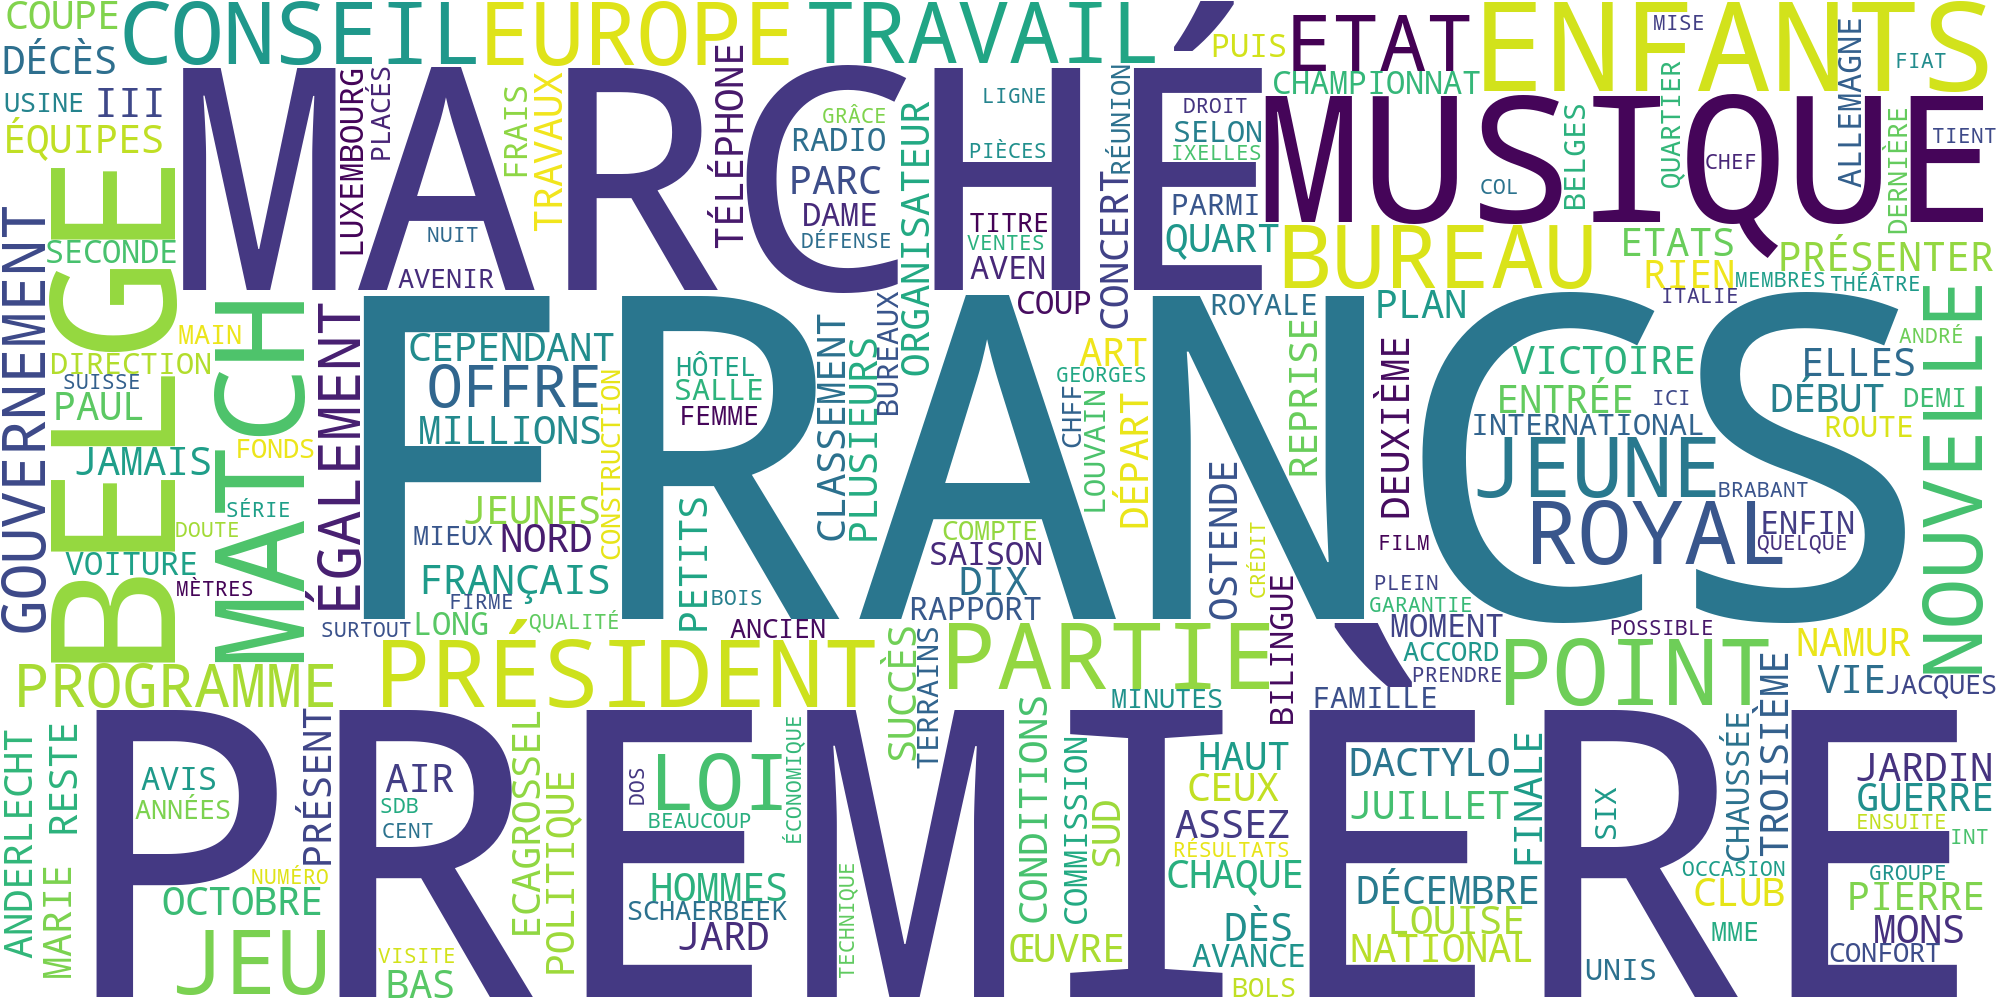

In [128]:
# Generate, store and display the wordcloud
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(TEMP_PATH, f"{YEAR}_iter5.png"))
Image(filename=os.path.join(TEMP_PATH, f"{YEAR}_iter5.png"))

## Named entities recognition

In [ ]:
%%time

# Loading the model
nlp = spacy.load('fr_core_news_md')

n = 1000000
text = open(f"../../data/tmp/{YEAR}_clean.txt", encoding='utf-8').read()[:n]

# Traiter le texte
doc = nlp(text)

# Compter les entités
people = defaultdict(int)
organisations = defaultdict(int)
locations = defaultdict(int)

for ent in doc.ents:
    if ent.label_ == "PER" and len(ent.text) > 3:
        people[ent.text] += 1
    elif ent.label_ == "ORG" and len(ent.text) > 3:
        organisations[ent.text] += 1
    elif ent.label_ == "LOC" and len(ent.text) > 3:
        locations[ent.text] += 1

# Trier et imprimer

sorted_people = sorted(people.items(), key=lambda kv: kv[1], reverse=True)
sorted_organisations = sorted(organisations.items(), key=lambda kv: kv[1], reverse=True)
sorted_locations = sorted(locations.items(), key=lambda kv: kv[1], reverse=True)

def print_entities(entity):
    for ent, freq in entity[:50]:
         print(f"{ent} apparait {freq} fois dans le corpus")


CPU times: total: 32.6 s
Wall time: 33.1 s


In [6]:
print_entities(sorted_people)

ÉLEVÉS apparait 3 fois dans le corpus
LOUIS BELGE apparait 3 fois dans le corpus
AUVELALS apparait 2 fois dans le corpus
LINGERIE BONNETER apparait 2 fois dans le corpus
AYRES apparait 2 fois dans le corpus
PHÉNIX WORKS apparait 2 fois dans le corpus
JOHN KENNEDY apparait 2 fois dans le corpus
CERTAINE apparait 2 fois dans le corpus
RAY GRASS apparait 2 fois dans le corpus
TIRLEMONT apparait 2 fois dans le corpus
JEAN XXIII apparait 2 fois dans le corpus
LOUIS LOUIS XVI apparait 2 fois dans le corpus
CERTAINE MESURE apparait 1 fois dans le corpus
VLCTN VICTN apparait 1 fois dans le corpus
SAMB MEURA apparait 1 fois dans le corpus
BELREF BÈMST apparait 1 fois dans le corpus
MERB SPR MERB apparait 1 fois dans le corpus
SOUVERNIN ANCIEN apparait 1 fois dans le corpus
NAPOLÉON GAGNE apparait 1 fois dans le corpus
LOUIS BEIGE apparait 1 fois dans le corpus
LIQUEURS apparait 1 fois dans le corpus
AVANTAGEA EXTRA apparait 1 fois dans le corpus
MEUNERIE PRÉSENTER RUE apparait 1 fois dans le co

In [7]:
print_entities(sorted_organisations)

GAND apparait 50 fois dans le corpus
OPEL apparait 41 fois dans le corpus
AVRIL apparait 38 fois dans le corpus
EUROPE apparait 27 fois dans le corpus
PART apparait 26 fois dans le corpus
ANTWERPSE apparait 26 fois dans le corpus
RENS apparait 23 fois dans le corpus
AGENCE apparait 22 fois dans le corpus
ANDERLECHT apparait 20 fois dans le corpus
FIAT apparait 18 fois dans le corpus
OUVR apparait 17 fois dans le corpus
SUETENS apparait 16 fois dans le corpus
CONGO apparait 14 fois dans le corpus
LÉOPOLD apparait 14 fois dans le corpus
ALLEMAGNE apparait 13 fois dans le corpus
FOLS apparait 13 fois dans le corpus
FIRME apparait 13 fois dans le corpus
PEUGEOT apparait 11 fois dans le corpus
PAYS apparait 11 fois dans le corpus
AUTOMOBILE apparait 11 fois dans le corpus
MAZOUT apparait 11 fois dans le corpus
TERMINA apparait 11 fois dans le corpus
ROBERT apparait 11 fois dans le corpus
AUTOS apparait 11 fois dans le corpus
DOLLAR apparait 10 fois dans le corpus
DÉSIRE apparait 10 fois dan

In [8]:
print_entities(sorted_locations)

MONS apparait 12 fois dans le corpus
ECRIRE apparait 7 fois dans le corpus
CONGO apparait 5 fois dans le corpus
TOUR apparait 4 fois dans le corpus
FIRME apparait 3 fois dans le corpus
GARE NORD apparait 3 fois dans le corpus
OPÉRETTE apparait 3 fois dans le corpus
BRUXELLOISE apparait 2 fois dans le corpus
BRUXELLOIS apparait 2 fois dans le corpus
GARE apparait 2 fois dans le corpus
BRUXELLES apparait 2 fois dans le corpus
INDE apparait 2 fois dans le corpus
AMIE apparait 2 fois dans le corpus
PRÉTOIRE apparait 2 fois dans le corpus
FRANCE apparait 2 fois dans le corpus
BRÈVE apparait 2 fois dans le corpus
BASIL apparait 2 fois dans le corpus
CONNUE apparait 2 fois dans le corpus
AMÉRICAINS apparait 2 fois dans le corpus
LAVAMAT apparait 2 fois dans le corpus
INTIMITÉ apparait 2 fois dans le corpus
CHARI VARSOVIE apparait 1 fois dans le corpus
ESN UTTECHT apparait 1 fois dans le corpus
CONGO KIVU apparait 1 fois dans le corpus
HÉVÉA IIMIMI IMAFOR apparait 1 fois dans le corpus
WESTLNC

## Sentiment analysis

### 1. Extraction of candidate sentences for sentiment analysis

Note: code generated by Gemini, reviewed and adjusted by us.

In [ ]:
import re
import spacy

files = sorted(f for f in os.listdir(DATA_PATH) if f"_{YEAR}-" in f)

# Le modèle md contient un vocabulaire de vecteurs : un mot absent (is_oov) est souvent une erreur d'OCR
nlp_check = spacy.load("fr_core_news_md", disable=["parser", "ner", "lemmatizer"])

# Mots de 1-2 lettres légitimes en français (les autres, comme "dd", "uu", "do", sont souvent des erreurs d'OCR)
SHORT_OK = {"a", "à", "y", "l", "d", "j", "m", "n", "s", "t", "c", "qu", "le", "la", "les", "de", "du", "un", "et",
            "en", "au", "il", "ne", "se", "sa", "ce", "on", "je", "tu", "me", "te", "ma", "ta", "ou", "où", "si",
            "ni", "nu", "va", "vu", "lu", "eu", "dû", "mi", "os", "or", "là", "ça", "ai", "as", "es", "est"}

def is_clean(sentence):
    """Heuristique : vrai si la phrase ne contient pas de mot visiblement abîmé par l'OCR."""
    if re.search(r"\w- \w", sentence):              # mot coupé en fin de ligne : "rè- trait"
        return False
    if re.search(r"\b[A-Z]\.$", sentence):          # phrase coupée sur une abréviation : "... M."
        return False
    doc = nlp_check(sentence)
    words = [t for t in doc if t.is_alpha]
    if len(words) < 8:
        return False
    for t in words:
        if t.is_oov:                                 # mot inconnu du vocabulaire spaCy
            return False
        if len(t.text) <= 2 and t.text.lower() not in SHORT_OK and not t.text.isupper():
            return False
    return True

candidates = []
for f in files:
    text = open(os.path.join(DATA_PATH, f), encoding="utf-8").read()
    # 1) Découpage grossier en phrases : ponctuation finale suivie d'une majuscule
    for s in re.split(r"(?<=[.!?])\s+(?=[A-ZÉÈÀ«])", text):
        s = s.strip()
        # 2) Longueur raisonnable (ni titre, ni bloc d'annonces)
        if not 70 < len(s) < 230:
            continue
        # 3) Presque uniquement des lettres et des espaces, peu de chiffres ou symboles parasites
        alpha = sum(ch.isalpha() or ch == " " for ch in s) / len(s)
        weird = len(re.findall(r"[■^\\|©®°“”]|\d", s))
        if alpha > 0.93 and weird <= 2 and is_clean(s):
            candidates.append((f.split("_")[2], s))

print(len(candidates), "phrases candidates")


with open(os.path.join(TEMP_PATH, f'{YEAR}_sentences.txt'), 'w', encoding='utf-8') as f:
    for c in candidates:
        #print(c)
        f.write(str(c) + '\n')
    

### 2. Extracted sentences

In [47]:
sentences = [
    "Sa première impression fut vive : l'homme qui l’avait fabriquée ne mettait pas d’amour-propre dans son travail.",
    "Koehler avait le respect du travail bien fait.",
    "L’incidence de cette vidange supplémentaire sur le budget final d’exploitation du véhicule est faible, minuscule même.",
    "Tandis que d’autre part, cette excellente précaution retarde l’usure du moteur en lui permettant de ne jamais travailler qu’avec un lubrifiant frais ou, en tout cas, peu contaminé.",
    "Evier, baignoire, carrelages sont plus blancs, plus brillants que jamais.",
    "Ses traits, presque brutaux, lui déplaisaient et lui déplaisait aussi bette expression de dédain amer qui ne la quittait guère.",
    "Devenez un artiste; alors vous trouverez le bonheur et vous gagnerez mieux votre vie.",
    "Les voix sont jolies, souples et bien assorties, elles conviennent admirablement à la musique de chambre.",
    "Sa cuisine renommée, ses chambres très confortables, son parc très reposant.",
    "Comme il est égoïste (tous les hommes le sont», aujourd’hui il la regrette.",
    "Bacon, avait découvert récemment un excellent vaccin contre le mal, précisément, qui vient de frapper le chercheur.",
    "Après un entretien de plus d’une demi-heure, le Premier ministre a déclaré qu’il avait trouvé l’ancien homme d’Etat « en très bonne forme ».",
    "Il ne semble pas que celte concession du superstitieux compositeur ait été trop mal récompensée.",
    "Si décevant lors des tournois d’avant-saison, le Racing a bien débuté le championnat.",
    "C'est qu'il nous semble que les œuvres lyriques s'accommodent mal d’arrangements pour fanfares et harmonies, les instruments à vent n'arrivant jamais à remplacer heureusement la voix humaine.",
    "Le Roi, le visage maculé, remonta, visiblement heureux de ce voyage souterrain.",
    "Auparavant, Sir Winston Churchill avait reçu là visite de Lady Churchill, qui' à déclaré ensuite que son mari semblait aller bien mieux et qu’il était tout à fait heureux.",
    "Une femme traduisait les sentiments de tous par ces simples mots : « Je suis très, très heureuse ».",
    "Reynaldo Hahn nous conta, autrefois, cette historiette : — Un des ses amis, pas très heureux en ménage, lui confiait ses peines.",
    "Et doublement heureux, puisqu'ils viennent de gagner un téléviseur et que ce téléviseur est un Novak !",
    "De plus, il contient un ingrédient spécial exclusif: avec Coral - qui fait si joliment chanter les couleurs - vos nylons blancs restent enfin blancs!",
    "Des phases de jeu admirablement construites ne sont pas assez souvent conclues comme elles le devraient et c’est la raison pour laquelle le Beerschot n’a marqué que dix buis en treize rencontres!",
    "Et la guerre entre les deux bandes n'a pas cessé au cours de ces dernières semaines, jalonnée de nouveaux cadavres, de nouveaux blessés."
]

### 3. Textblob-FR

In [ ]:
# Instantiate Blobber
tb = Blobber(pos_tagger=PatternTagger(), analyzer=PatternAnalyzer())

# Create function get_sentiment
def get_sentiment(input_text):
    blob = tb(input_text)
    polarity, subjectivity = blob.sentiment
    polarity_perc = f"{100*abs(polarity):.0f}"
    subjectivity_perc = f"{100*subjectivity:.0f}"
    if polarity > 0:
        polarity_str = f"{polarity_perc}% positive"
    elif polarity < 0:
        polarity_str = f"{polarity_perc}% negative"
    else:
        polarity_str = "neutral"
    if subjectivity > 0:
        subjectivity_str = f"{subjectivity_perc}% subjective"
    else:
        subjectivity_str = "perfectly objective"
    print(f"This text is {polarity_str} and {subjectivity_str}.")


cpt = 1
for s in sentences:
    print(f"Phrase {cpt} : {s} :")
    get_sentiment(s)
    cpt += 1



### 4. Transformers

In [ ]:


tokenizer = AutoTokenizer.from_pretrained("philschmid/pt-tblard-tf-allocine")
model = AutoModelForSequenceClassification.from_pretrained("philschmid/pt-tblard-tf-allocine")

sentiment_analyser = pipeline('sentiment-analysis', model=model, tokenizer=tokenizer)

for cpt, s in enumerate(sentences, start=1):
    result = sentiment_analyser(s)   
    print(f"Phrase {cpt}: '{s}' -> {result}")




Loading weights: 100%|██████████| 201/201 [00:00<00:00, 17235.46it/s]


Phrase 1: 'Sa première impression fut vive : l'homme qui l’avait fabriquée ne mettait pas d’amour-propre dans son travail.' -> [{'label': 'NEGATIVE', 'score': 0.7891836166381836}]
Phrase 2: 'Koehler avait le respect du travail bien fait.' -> [{'label': 'POSITIVE', 'score': 0.7778602242469788}]
Phrase 3: 'L’incidence de cette vidange supplémentaire sur le budget final d’exploitation du véhicule est faible, minuscule même.' -> [{'label': 'NEGATIVE', 'score': 0.9648330807685852}]
Phrase 4: 'Tandis que d’autre part, cette excellente précaution retarde l’usure du moteur en lui permettant de ne jamais travailler qu’avec un lubrifiant frais ou, en tout cas, peu contaminé.' -> [{'label': 'POSITIVE', 'score': 0.8351742029190063}]
Phrase 5: 'Evier, baignoire, carrelages sont plus blancs, plus brillants que jamais.' -> [{'label': 'POSITIVE', 'score': 0.6513355374336243}]
Phrase 6: 'Ses traits, presque brutaux, lui déplaisaient et lui déplaisait aussi bette expression de dédain amer qui ne la quit